# ECE 3715 Final Project
## Part I: Gaussian detection - Steps 1 and 2

**Christian Ruelas - Steps 1-2 and initial detector helpers**  
**Seed: 791607502, drawn once November 27, 2026**  
**Part II choice: Track A5, medical screening (separate notebook, pending).**

We derive the likelihood-ratio detector, show the equal-covariance cancellation,
and compare its probability of error with a mean-difference detector. Each
simulation prints its trial count, standard error, and difference from theory.
Steps 3-5 and the full-project runtime check remain to be completed.

In [1]:
from pathlib import Path
from time import perf_counter
import csv
import json
import platform

START_TIME = perf_counter()
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import multivariate_normal
from finallib import (log_likelihood_ratio, linear_discriminant,
                      q_function, empirical_error_rate)

SEED = 791607502  # drawn once 2026-11-27; do not change
rng = np.random.default_rng(SEED)
rng_part1 = rng.spawn(1)[0]  # one generator for all of Part I

FIGURES, RESULTS = Path("figures"), Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180,
                     "font.size": 11, "axes.grid": True, "grid.alpha": 0.2})

def save_table(name, rows):
    with (RESULTS / f"{name}.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def show_table(title, rows):
    def fmt(v):
        return f"{v:.9g}" if isinstance(v, (float, np.floating)) else str(v)
    keys = list(rows[0])
    lines = ["| " + " | ".join(keys) + " |", "|" + "---|" * len(keys)]
    lines += ["| " + " | ".join(fmt(row[k]) for k in keys) + " |" for row in rows]
    display(Markdown(f"**{title}**\n\n" + "\n".join(lines)))

mu0 = np.array([0., 0.])
mu1 = np.array([4., 2.])
S = np.array([[4., 2.], [2., 4.]])
mean_difference = mu1 - mu0
print(f"Fixed seed: {SEED}; one child stream for Part I.")

Fixed seed: 791607502; one child stream for Part I.


## Step 1: The likelihood ratio and the optimal rule

### General Gaussian model

Let $H_i: X\sim\mathcal N(\mu_i,\Sigma_i)$ in $d$ dimensions, with positive
definite covariances. The log density is
$$\log f_i(x)=-\frac d2\log(2\pi)-\frac12\log\det\Sigma_i
-\frac12(x-\mu_i)^T\Sigma_i^{-1}(x-\mu_i).$$
Subtracting the two log densities gives, with the convention $\ell=\log(f_1/f_0)$,
$$\begin{aligned}
\ell(x)&=\frac12x^T(\Sigma_0^{-1}-\Sigma_1^{-1})x
+(\Sigma_1^{-1}\mu_1-\Sigma_0^{-1}\mu_0)^Tx\\
&\quad+\frac12(\mu_0^T\Sigma_0^{-1}\mu_0-\mu_1^T\Sigma_1^{-1}\mu_1)
-\frac12\log\frac{\det\Sigma_1}{\det\Sigma_0}.
\end{aligned}$$
The quadratic and log-determinant terms must be retained when covariances differ.
`log_likelihood_ratio` implements the equivalent centered form using Cholesky
solves. We check it against independently evaluated SciPy log densities below.

### Equal covariances: explicit cancellation

With $\Sigma_0=\Sigma_1=\Sigma$, the determinant ratio is one and
$$\begin{aligned}
\ell(x)&=-\frac12\left[x^T\Sigma^{-1}x-2\mu_1^T\Sigma^{-1}x
+\mu_1^T\Sigma^{-1}\mu_1\right]\\
&\quad+\frac12\left[x^T\Sigma^{-1}x-2\mu_0^T\Sigma^{-1}x
+\mu_0^T\Sigma^{-1}\mu_0\right]\\
&=\underbrace{-\frac12x^T\Sigma^{-1}x+\frac12x^T\Sigma^{-1}x}_{0}
+(\mu_1-\mu_0)^T\Sigma^{-1}x
-\frac12(\mu_1^T\Sigma^{-1}\mu_1-\mu_0^T\Sigma^{-1}\mu_0)\\
&=w^Tx-\tau,
\end{aligned}$$
where
$$w=\Sigma^{-1}(\mu_1-\mu_0),\qquad
\tau=\tfrac12(\mu_0+\mu_1)^Tw.$$
For equal priors and equal misclassification costs, choose $H_1$ if
$\ell(x)>0$, equivalently $w^Tx>\tau$. Ties are assigned to $H_0$; the
continuous nonsingular model gives the boundary probability zero.

### Numerical rule and direction

For the supplied setup,
$$\Sigma^{-1}=\frac1{12}\begin{bmatrix}4&-2\\-2&4\end{bmatrix},\quad
w=\frac1{12}\begin{bmatrix}4&-2\\-2&4\end{bmatrix}
\begin{bmatrix}4\\2\end{bmatrix}=\begin{bmatrix}1\\0\end{bmatrix},
\quad\tau=2.$$
Thus the rule is $x_1>2$, a vertical boundary in the measurement plane.

The mean difference $[4,2]^T$ points toward the other class center, whereas
$w=[1,0]^T$ accounts for the correlated noise through $\Sigma^{-1}$.
The second coordinate's mean shift is exactly what the correlation predicts
from the first: $E[X_2\mid X_1=x_1,H_0]=E[X_2\mid X_1=x_1,H_1]=x_1/2$.
Consequently, after observing $X_1$, observing $X_2$ adds no class information.
Projecting along the mean difference nevertheless adds that coordinate's noise,
reducing standardized separation.

Mean difference: [4. 2.]
Optimal w: [1. 0.]
Optimal threshold tau = 2; boundary x1 = 2


**Step 1 numerical checks (deterministic)**

| check | max_abs_difference |
|---|---|
| equal covariance vs SciPy logpdf | 1.77635684e-15 |
| unequal covariance vs SciPy logpdf | 6.66133815e-16 |
| equal covariance: linear vs general | 0 |

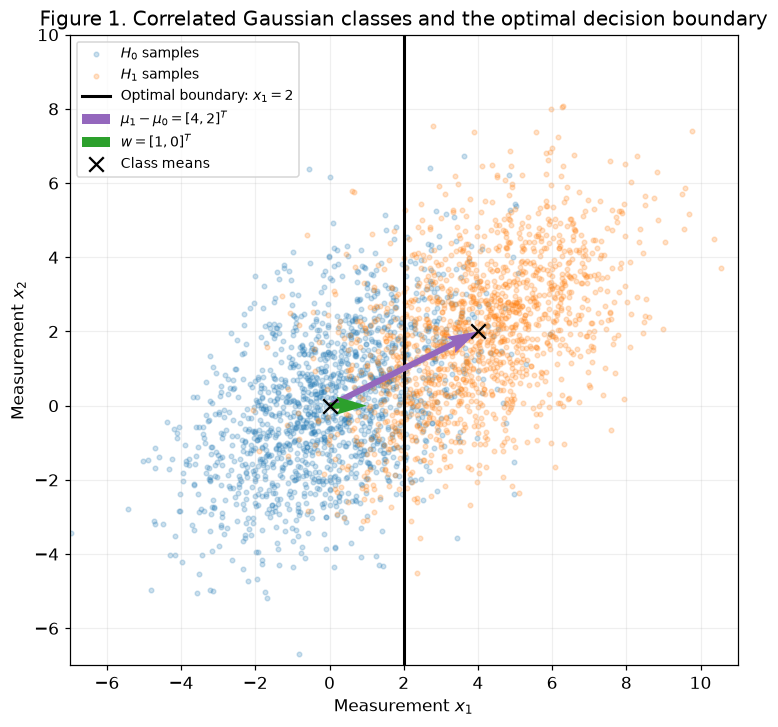

In [2]:
w = np.linalg.solve(S, mean_difference)
tau = float((mu0 + mu1) @ w / 2)
print("Mean difference:", mean_difference)
print("Optimal w:", w)
print(f"Optimal threshold tau = {tau:g}; boundary x1 = {tau:g}")
np.testing.assert_allclose(w, [1, 0], atol=1e-14)
np.testing.assert_allclose(tau, 2, atol=1e-14)

# Deterministic numerical validation: no additional random stream.
probes = np.array([[0., 0.], [2., 1.], [4., 2.], [-3., 5.], [8., -1.]])
checks = []
for label, covariance1 in [("equal covariance", S),
                           ("unequal covariance", np.array([[2., -1.], [-1., 2.]]))]:
    own = log_likelihood_ratio(probes, mu0, S, mu1, covariance1)
    reference = (multivariate_normal.logpdf(probes, mean=mu1, cov=covariance1)
                 - multivariate_normal.logpdf(probes, mean=mu0, cov=S))
    gap = float(np.max(np.abs(own - reference)))
    np.testing.assert_allclose(own, reference, rtol=1e-12, atol=1e-12)
    checks.append({"check": label + " vs SciPy logpdf", "max_abs_difference": gap})
linear_gap = float(np.max(np.abs(linear_discriminant(probes, mu0, mu1, S)
                                 - log_likelihood_ratio(probes, mu0, S, mu1, S))))
np.testing.assert_allclose(linear_gap, 0, atol=1e-12)
checks.append({"check": "equal covariance: linear vs general", "max_abs_difference": linear_gap})
show_table("Step 1 numerical checks (deterministic)", checks)
save_table("step1_checks", checks)

n_plot_per_class = 1500
cloud0 = rng_part1.multivariate_normal(mu0, S, n_plot_per_class)
cloud1 = rng_part1.multivariate_normal(mu1, S, n_plot_per_class)
fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
ax.scatter(*cloud0.T, s=9, alpha=0.22, color="tab:blue", label=r"$H_0$ samples")
ax.scatter(*cloud1.T, s=9, alpha=0.22, color="tab:orange", label=r"$H_1$ samples")
ax.axvline(tau, color="black", lw=2, label=r"Optimal boundary: $x_1=2$")
# Exact vectors, not unit directions; both start at mu0.
ax.quiver(0, 0, *mean_difference, angles="xy", scale_units="xy", scale=1,
          color="tab:purple", width=0.009, zorder=5, label=r"$\mu_1-\mu_0=[4,2]^T$")
ax.quiver(0, 0, *w, angles="xy", scale_units="xy", scale=1,
          color="tab:green", width=0.009, zorder=6, label=r"$w=[1,0]^T$")
ax.scatter(*np.vstack([mu0, mu1]).T, marker="x", s=90, color="black", zorder=7,
           label="Class means")
ax.set(xlabel=r"Measurement $x_1$", ylabel=r"Measurement $x_2$",
       title="Figure 1. Correlated Gaussian classes and the optimal decision boundary",
       xlim=(-7, 11), ylim=(-7, 10))
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", fontsize=9)
fig.savefig(FIGURES / "figure1_optimal_boundary.png")
plt.show()

**Figure 1 interpretation.** The two sample clouds tilt upward because the
coordinates are positively correlated. The mean-difference arrow follows that
tilt, while the optimal weight arrow is horizontal and normal to the vertical
decision boundary. The arrows show the actual vectors, so their lengths differ.
The detector chooses $H_1$ to the right of the boundary and $H_0$ to its left.
The 1,500 observations per class are only for visualization; the error-rate
verification below uses a separate draw of 1,000,000 per class.

## Step 2: Deflection coefficient and probability of error

### Optimal projection

Write $\Delta\mu=\mu_1-\mu_0$ and define the squared Mahalanobis distance
$$\delta^2=\Delta\mu^T\Sigma^{-1}\Delta\mu=4,\qquad\delta=2.$$
A linear projection of a Gaussian is Gaussian, so $T=w^TX$ obeys
$$T\mid H_i\sim\mathcal N(m_i,v),\qquad
m_i=w^T\mu_i,\quad v=w^T\Sigma w=\delta^2.$$
Here $m_0=0$, $m_1=4$, and $v=4$; the threshold $\tau=2$ is the midpoint.
Since $m_1-m_0=\delta^2$, the threshold is $\delta/2$ standard deviations
from either projected mean. Defining $Q(z)=\frac12\operatorname{erfc}(z/\sqrt2)$,
$$P_{FA}=Q\left(\frac{\tau-m_0}{\sqrt v}\right)=Q(\delta/2),\qquad
P_M=Q\left(\frac{m_1-\tau}{\sqrt v}\right)=Q(\delta/2),$$
$$P_e^*=\tfrac12(P_{FA}+P_M)=Q(1).$$

### Naive mean-difference projection

For any direction $a$ with $a^T\Delta\mu>0$, the best threshold for that
projection under equal priors is $\tau_a=a^T(\mu_0+\mu_1)/2$. Its effective
deflection and error are
$$\delta_a=\frac{a^T\Delta\mu}{\sqrt{a^T\Sigma a}},\qquad
P_{e,a}=Q(\delta_a/2).$$
Taking $a=\Delta\mu=[4,2]^T$ gives
$$m_{0,a}=0,\quad m_{1,a}=20,\quad v_a=112,\quad\tau_a=10,\quad
\delta_a=\frac{20}{\sqrt{112}}=\frac5{\sqrt7}.$$
This uses the naive detector's **own optimal threshold** rather than reusing
the optimal detector's threshold of two.

### Monte Carlo design and uncertainty

Draw $n_0=n_1=10^6$ independent observations from the respective classes.
For each detector, estimate the two conditional error probabilities, then
average with the equal priors. The plug-in standard error is
$$\widehat{\mathrm{SE}}(\widehat P_e)=\frac12\sqrt{
\frac{\widehat P_{FA}(1-\widehat P_{FA})}{n_0}
+\frac{\widehat P_M(1-\widehat P_M)}{n_1}}.$$
The two detectors share the same class samples. Their error estimates are
therefore correlated; the standard error of their difference is calculated
from paired error-indicator differences, not by treating the estimates as
independent. Approximate 95% intervals use $\widehat P_e\pm1.96\,\widehat{SE}$.

In [3]:
delta_sq = float(mean_difference @ w)
delta = np.sqrt(delta_sq)
a = mean_difference.copy()
tau_naive = float(a @ (mu0 + mu1) / 2)
delta_naive = float(a @ mean_difference / np.sqrt(a @ S @ a))
pe_optimal = float(q_function(delta / 2))
pe_naive = float(q_function(delta_naive / 2))
projection_rows = []
for name, direction, threshold, separation in [
    ("Optimal", w, tau, delta), ("Naive", a, tau_naive, delta_naive)
]:
    projection_rows.append({"detector": name, "mean_H0": float(direction @ mu0),
                            "mean_H1": float(direction @ mu1),
                            "variance": float(direction @ S @ direction),
                            "threshold": threshold, "delta": float(separation)})
show_table("Projection means, variances, and thresholds", projection_rows)
save_table("step2_projections", projection_rows)
np.testing.assert_allclose([delta_sq, delta, tau_naive], [4, 2, 10], atol=1e-14)
np.testing.assert_allclose([pe_optimal, delta_naive, pe_naive],
                          [0.1586553, 1.889822, 0.1723521], atol=5e-7, rtol=0)

N_PER_CLASS = 1_000_000
X0 = rng_part1.multivariate_normal(mu0, S, N_PER_CLASS)
X1 = rng_part1.multivariate_normal(mu1, S, N_PER_CLASS)
# Keep samples available for the future ROC step. Helpers return centered scores.
scores0_optimal = linear_discriminant(X0, mu0, mu1, S)
scores1_optimal = linear_discriminant(X1, mu0, mu1, S)
scores0_naive = X0 @ a - tau_naive
scores1_naive = X1 @ a - tau_naive

rows, errors = [], {}
for name, s0, s1, theory in [
    ("Optimal", scores0_optimal, scores1_optimal, pe_optimal),
    ("Naive", scores0_naive, scores1_naive, pe_naive)
]:
    error0, error1 = s0 > 0, s1 <= 0
    pfa = empirical_error_rate(error0, np.zeros(N_PER_CLASS, dtype=bool))
    pm = empirical_error_rate(s1 > 0, np.ones(N_PER_CLASS, dtype=bool))
    estimate = (pfa + pm) / 2
    se = 0.5 * np.sqrt((pfa*(1-pfa) + pm*(1-pm)) / N_PER_CLASS)
    rows.append({"detector": name, "n_per_class": N_PER_CLASS,
                 "analytic_Pe": theory, "simulated_Pe": estimate,
                 "standard_error": float(se), "MC_minus_theory": estimate-theory,
                 "difference_in_SE": float((estimate-theory)/se),
                 "CI95_low": float(estimate-1.96*se), "CI95_high": float(estimate+1.96*se),
                 "P_FA_MC": pfa, "P_miss_MC": pm})
    errors[name] = (error0, error1)
show_table("Error-rate verification: 1,000,000 trials per class, per detector", rows)
save_table("step2_error_rates", rows)

paired0 = errors["Naive"][0].astype(float) - errors["Optimal"][0]
paired1 = errors["Naive"][1].astype(float) - errors["Optimal"][1]
paired_gap = float((paired0.mean() + paired1.mean()) / 2)
paired_se = float(0.5*np.sqrt((paired0.var(ddof=1)+paired1.var(ddof=1))/N_PER_CLASS))
gap_theory = pe_naive - pe_optimal
comparison = [{"n_per_class": N_PER_CLASS, "analytic_error_increase": gap_theory,
               "paired_MC_increase": paired_gap, "paired_standard_error": paired_se,
               "MC_minus_theory": paired_gap-gap_theory,
               "difference_in_SE": (paired_gap-gap_theory)/paired_se,
               "extra_errors_relative_to_optimal_percent": 100*gap_theory/pe_optimal,
               "avoidable_fraction_of_naive_errors_percent": 100*gap_theory/pe_naive}]
show_table("Paired comparison and relative loss", comparison)
save_table("step2_comparison", comparison)
display(Markdown(
    f"**Numerical interpretation.** The optimal analytic error is {pe_optimal:.7f} "
    f"and the naive error is {pe_naive:.7f}. The naive detector makes "
    f"{100*gap_theory/pe_optimal:.2f}% more errors than optimal; equivalently, "
    f"{100*gap_theory/pe_naive:.2f}% of its errors are avoidable. "
    f"On the shared samples, the measured reduction is {paired_gap:.7f} "
    f"with paired standard error {paired_se:.7f}. "
    + " ".join(f"{r['detector']} differs from theory by {r['difference_in_SE']:.2f} SE."
               for r in rows)
))

**Projection means, variances, and thresholds**

| detector | mean_H0 | mean_H1 | variance | threshold | delta |
|---|---|---|---|---|---|
| Optimal | 0 | 4 | 4 | 2 | 2 |
| Naive | 0 | 20 | 112 | 10 | 1.88982237 |

**Error-rate verification: 1,000,000 trials per class, per detector**

| detector | n_per_class | analytic_Pe | simulated_Pe | standard_error | MC_minus_theory | difference_in_SE | CI95_low | CI95_high | P_FA_MC | P_miss_MC |
|---|---|---|---|---|---|---|---|---|---|---|
| Optimal | 1000000 | 0.158655254 | 0.1584765 | 0.000258226353 | -0.000178753931 | -0.69223737 | 0.157970376 | 0.158982624 | 0.158474 | 0.158479 |
| Naive | 1000000 | 0.172352111 | 0.1720965 | 0.000266907378 | -0.000255611003 | -0.957676798 | 0.171573362 | 0.172619638 | 0.171652 | 0.172541 |

**Paired comparison and relative loss**

| n_per_class | analytic_error_increase | paired_MC_increase | paired_standard_error | MC_minus_theory | difference_in_SE | extra_errors_relative_to_optimal_percent | avoidable_fraction_of_naive_errors_percent |
|---|---|---|---|---|---|---|---|
| 1000000 | 0.0136968571 | 0.01362 | 0.000182317534 | -7.6857072e-05 | -0.421556118 | 8.63309391 | 7.9470202 |

**Numerical interpretation.** The optimal analytic error is 0.1586553 and the naive error is 0.1723521. The naive detector makes 8.63% more errors than optimal; equivalently, 7.95% of its errors are avoidable. On the shared samples, the measured reduction is 0.0136200 with paired standard error 0.0001823. Optimal differs from theory by -0.69 SE. Naive differs from theory by -0.96 SE.

### Connection to MP2 Step 6

In the scalar Gaussian detection model from MP2, $\delta$ reduces to the mean
separation divided by the common noise standard deviation, $A/\sigma$.
In multiple dimensions, Mahalanobis separation measures that same standardized
signal separation after accounting for coordinate scales and correlations,
and equals the separation-to-standard-deviation ratio of the optimal projection.

### What remains

Step 3 will sweep thresholds over pooled scores to build the ROC; Steps 4 and
5 will study unequal covariances and estimated parameters. Part II is Track A5,
medical screening, and will use a separate notebook and its own spawned stream.
The code and analytic results above are synthetic detection experiments.

In [4]:
runtime = {"completed_steps": [1, 2], "seed": SEED,
           "seconds": perf_counter() - START_TIME,
           "python": platform.python_version(), "numpy": np.__version__,
           "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
           "monte_carlo_samples_per_class": N_PER_CLASS}
(RESULTS / "part1_runtime.json").write_text(json.dumps(runtime, indent=2) + "\n", encoding="utf-8")
print(f"Steps 1-2 runtime: {runtime['seconds']:.2f} seconds.")
print("This is a partial notebook; the full Part I runtime must be checked after Steps 3-5.")

Steps 1-2 runtime: 14.09 seconds.
This is a partial notebook; the full Part I runtime must be checked after Steps 3-5.
